# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

![.](part1.png)


$(d_c/2m)^2$ это ожидаемая доля рёбер внутри сообщества в случайном графе с теми же степенями вершин. Его вычитают, чтобы учитывать только значимые связи (которых внутри группы больше, чем если бы соединили случайно)

$Q > 0$ значит, что внутри сообществ рёбер больше, чем в случайном графе. Здесь $Q \approx 0.42$, так что все хорошо.

$Q$ не вероятность, это разность двух долей, она может быть отрицательной

## Задание 2. Клетки сердца эмбриона мыши E18

**Данные:** [1k Heart Cells from an E18 mouse (v3 chemistry)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0), файл Feature / cell matrix HDF5 (filtered).

In [85]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [86]:
adata = sc.read_10x_h5("data/heart_1k_v3_filtered_feature_bc_matrix.h5")
adata.var_names_make_unique()
adata

/home/anna/miniconda3/envs/sc_pbmc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/anna/miniconda3/envs/sc_pbmc/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 1011 × 31053
    var: 'gene_ids', 'feature_types', 'genome'

## 1. QC

У мыши митохондриальные гены начинаются с `mt-`.

In [87]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

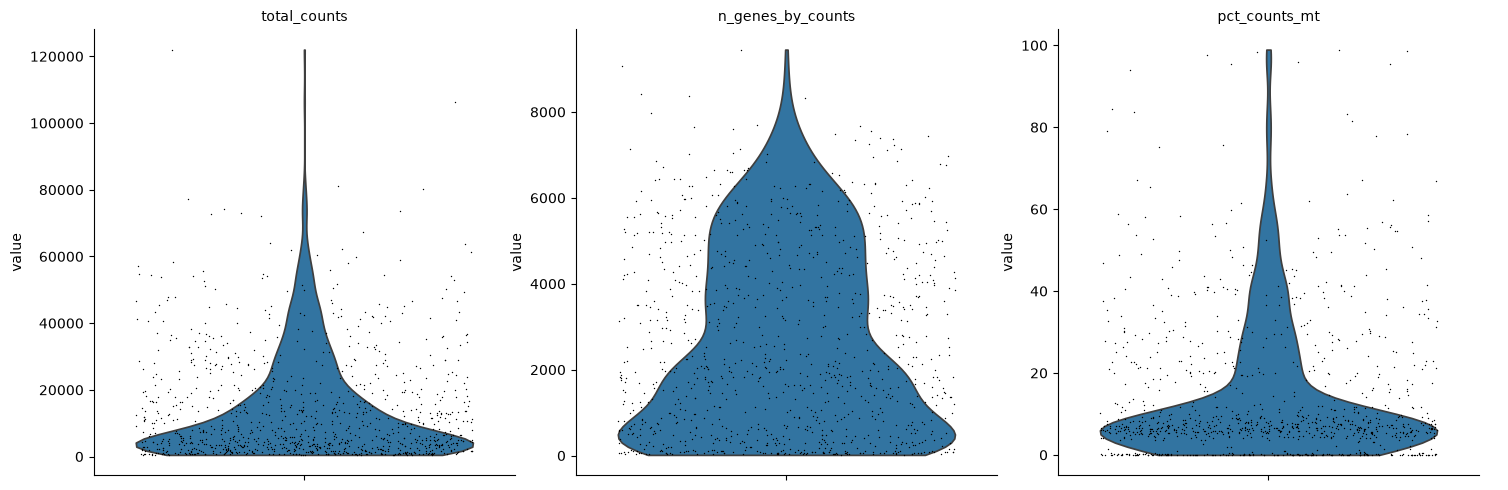

In [88]:
sc.pl.violin(adata, ["total_counts", "n_genes_by_counts", "pct_counts_mt"], jitter=0.4, multi_panel=True)

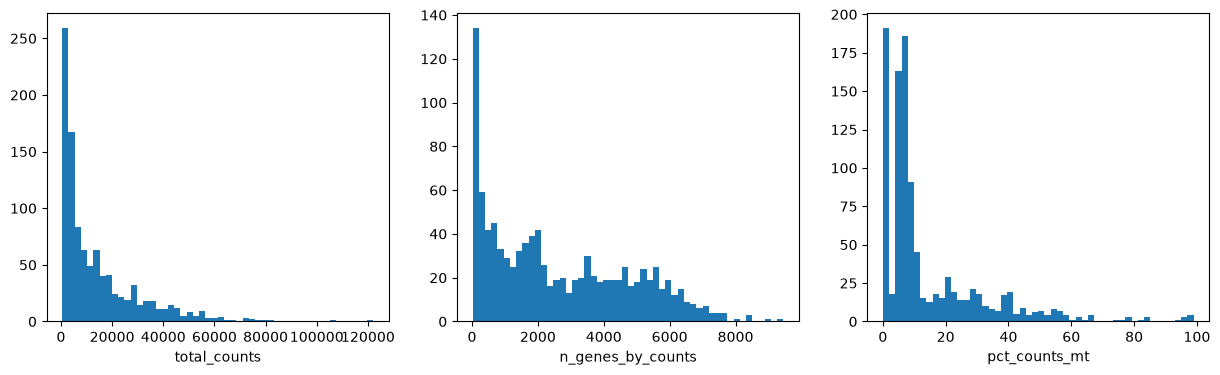

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(adata.obs["total_counts"], bins=50)
axes[0].set(xlabel="total_counts")
axes[1].hist(adata.obs["n_genes_by_counts"], bins=50)
axes[1].set(xlabel="n_genes_by_counts")
axes[2].hist(adata.obs["pct_counts_mt"], bins=50)
axes[2].set(xlabel="pct_counts_mt")
plt.show()

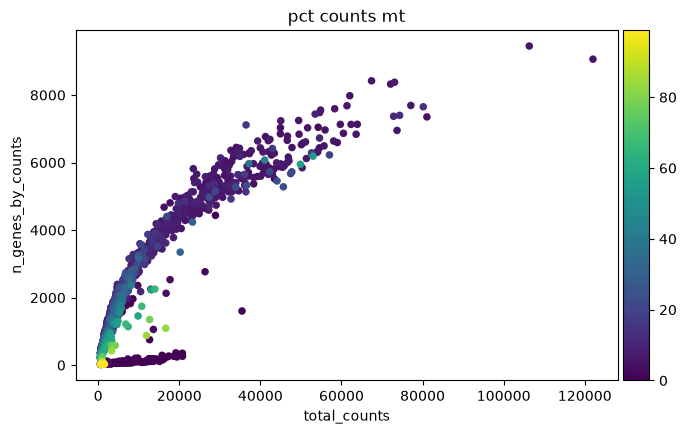

In [90]:
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

In [91]:
n_before = adata.n_obs

sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 7500) &
    (adata.obs["pct_counts_mt"] < 30)
].copy()

print("Клеток до QC:", n_before)
print("Клеток после QC:", adata.n_obs)
print("Генов после QC:", adata.n_vars)

Клеток до QC: 1011
Клеток после QC: 722
Генов после QC: 16619


**Почему такие пороги:**
- `min_genes=200` - на гистограмме есть пик клеток с маленьким числом генов (меньше 200) - это пустые капли или разрушенные клетки
- `n_genes_by_counts < 7500` - убираем несколько клеток с очень большим числом генов, так как дублеты
- `pct_counts_mt < 30` - клетки с mt выше 30% скорее всего повреждены. В сердце порог выше, чем 5% в PBMC, потому что у кардиомиоцитов много митохондрий и высокая доля mt-РНК это нормально
- `min_cells=3` - убираем гены, которые примерно нигде не встречаются

## 2. Нормализация и HVG

In [92]:
adata.layers["counts"] = adata.X.copy()

sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

print("Число HVG:", adata.var["highly_variable"].sum())

Число HVG: 2000


**Зачем HVG:** большинство генов почти не меняются между клетками и добавляют только шум. HVG - гены, которые сильно различаются между клетками, они несут информацию о типах клеток

**Почему 2000:** Генов после QC около 16к, 2к достаточно, чтобы захватить маркеры всех основных популяций

## 3. PCA

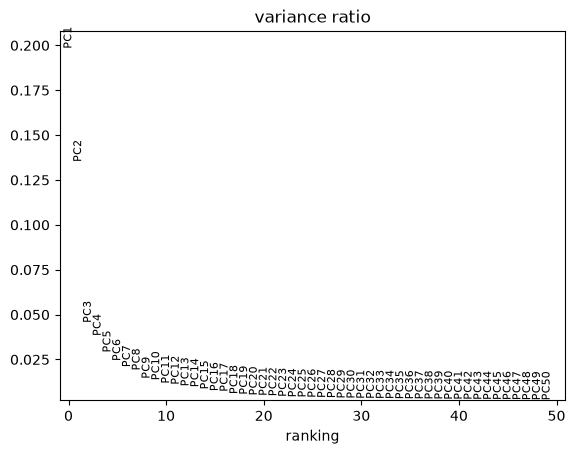

In [93]:
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)
sc.pl.pca_variance_ratio(adata, n_pcs=50)

In [94]:
print(np.round(adata.uns["pca"]["variance_ratio"][:25], 3))

[0.198 0.135 0.045 0.038 0.029 0.024 0.021 0.019 0.014 0.013 0.012 0.011
 0.01  0.01  0.008 0.007 0.007 0.006 0.005 0.005 0.005 0.005 0.004 0.004
 0.004]


**Выбор числа PC:** первые две компоненты объясняют больше всего дисперсии, дальше доля резко падает, и  после 20 компоненты график становится почти 0. Берем `n_pcs=20`, чтобы не потерять мелкие популяции

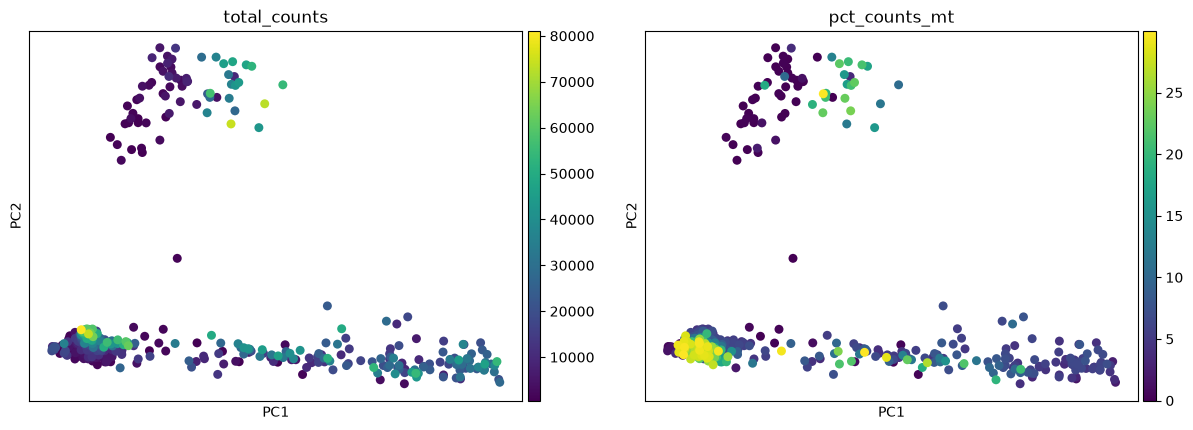

In [95]:
sc.pl.pca(adata, color=["total_counts", "pct_counts_mt"])

## 4. Граф соседей и Leiden

In [96]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20, random_state=42)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden")

In [100]:
print("Число кластеров:", adata.obs["leiden"].nunique())
print(adata.obs["leiden"].value_counts())

Число кластеров: 14
leiden
0     144
1     111
2      97
3      62
4      57
5      53
6      35
7      30
8      28
9      25
10     24
11     21
12     20
13     15
Name: count, dtype: int64


**Параметры:**
- `n_neighbors=15` - клеток около 700, так что 15 нормально. Если брать больше, мелкие группы начнут сливаться с соседними
- `n_pcs=20` - по графику объяснённой дисперсии
- `resolution=0.5` - чуть меньше стандартного 1.0, потому что клеток мало. При 1.0 крупные группы начинают дробиться на мелкие

## 5. UMAP и t-SNE

In [101]:
sc.tl.umap(adata, random_state=42)
sc.tl.tsne(adata, use_rep="X_pca", n_pcs=20, random_state=42)

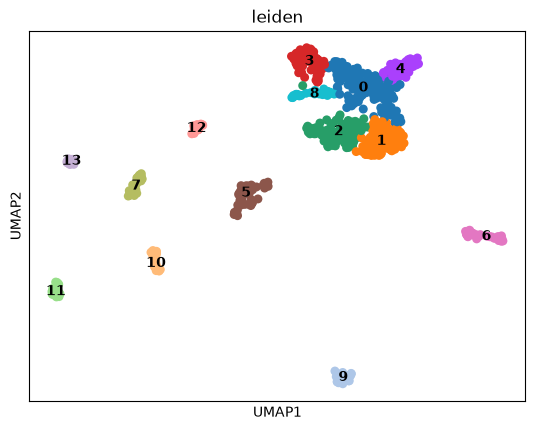

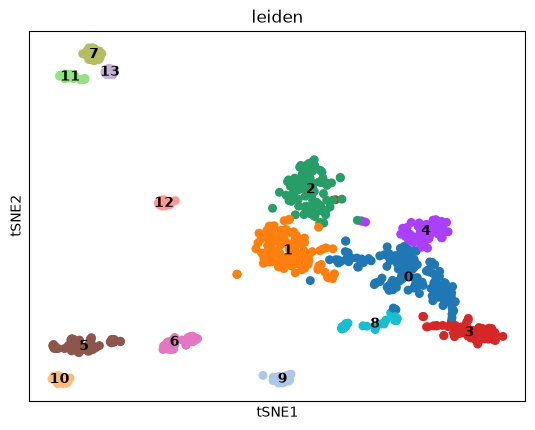

In [102]:
sc.pl.umap(adata, color="leiden", legend_loc="on data")
sc.pl.tsne(adata, color="leiden", legend_loc="on data")

Окрашиваем UMAP по QC-метрике и двум генам: `Tnnt2` (кардиомиоциты) и `Col1a1` (фибробласты). Первая картинка с номерами кластеров для сравнения

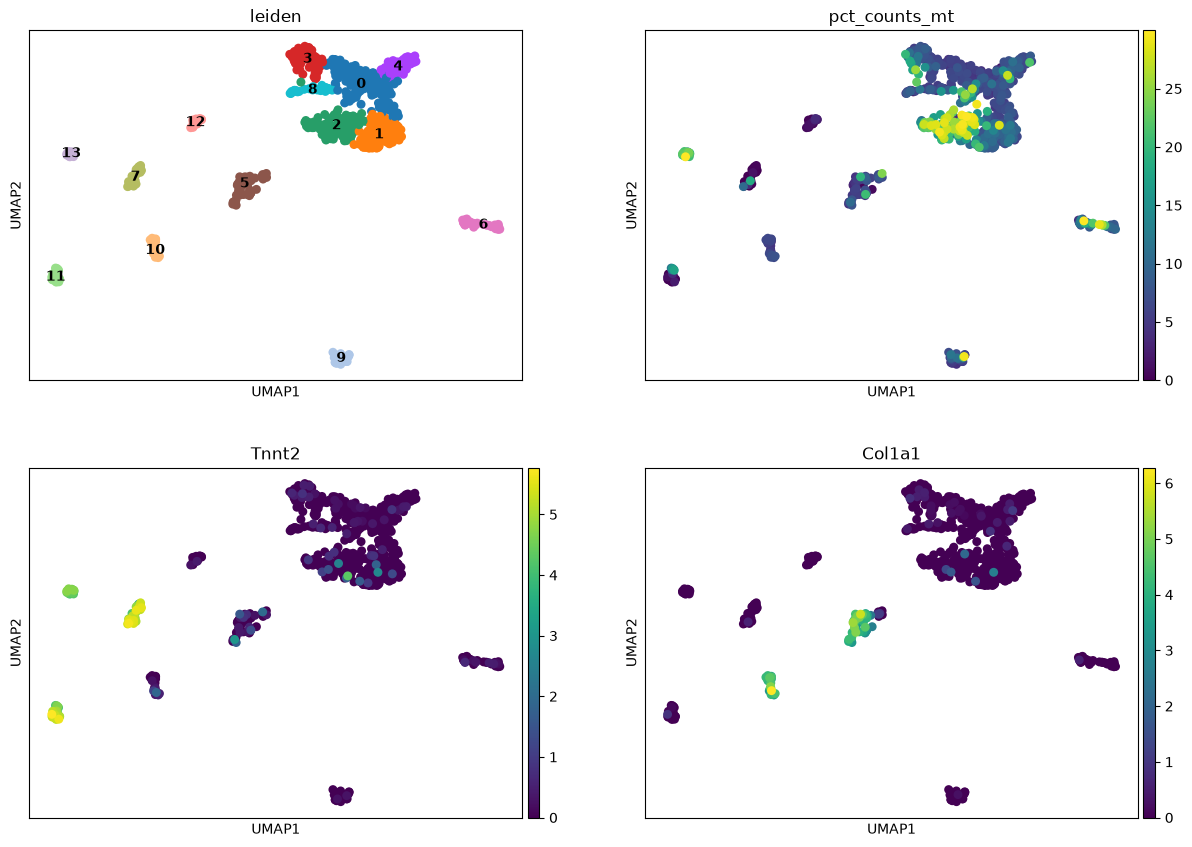

In [103]:
sc.pl.umap(adata, color=["leiden", "pct_counts_mt", "Tnnt2", "Col1a1"], legend_loc="on data", ncols=2)

То же самое по кластерам:

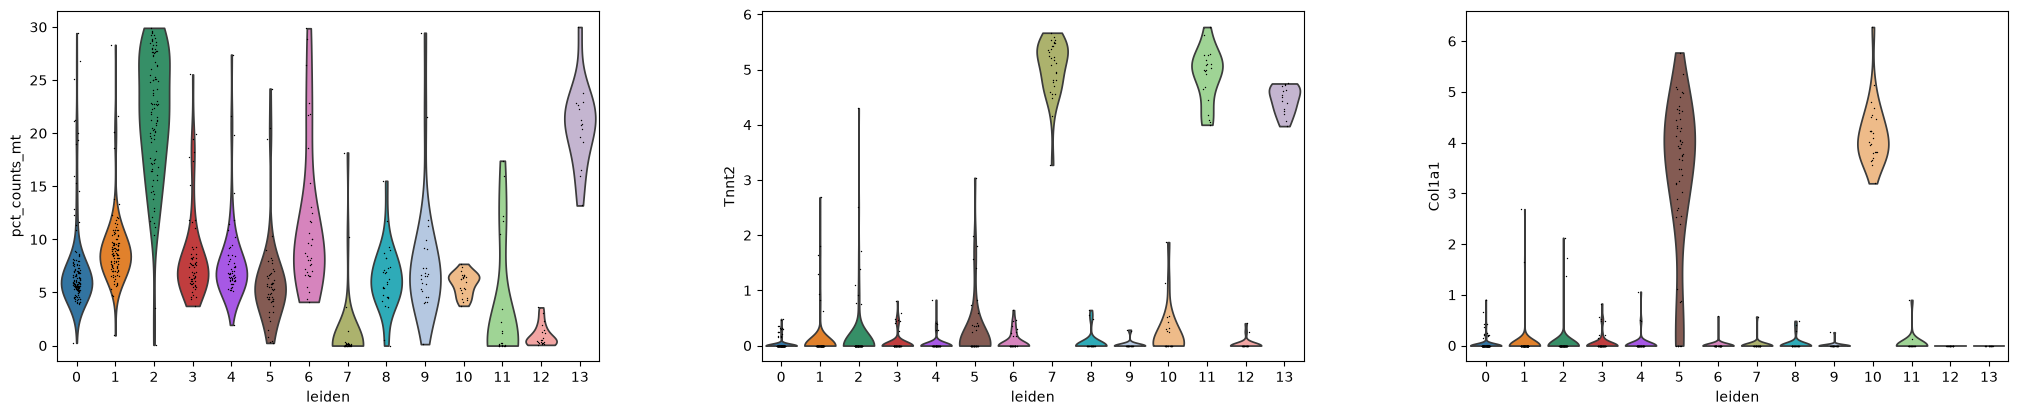

In [104]:
sc.pl.violin(adata, ["pct_counts_mt", "Tnnt2", "Col1a1"], groupby="leiden")

**Что видно:**
- UMAP и t-SNE показывают похожие группы, кластеры Leiden на обеих картинках лежат компактно
- Большая часть клеток образует одно крупное облако из нескольких кластеров
- `Tnnt2` сильно экспрессируется в кластерах 7, 11 и 13, `Col1a1` в кластерах 5 и 10. Клеток с высокой экспрессией обоих генов нет
- Высокая доля mt в кластере 2 (в большом облаке) и в кластере 13 (кардиомиоциты). У кардиомиоцитов это нормально, а кластер 2 может вилимо худшего качества

## 6. Биологический вывод

Проверим ещё несколько известных генов:
- `Cdh5` - эндотелий
- `Cd3d` - T-клетки
- `Hbb-bs` - эритроциты

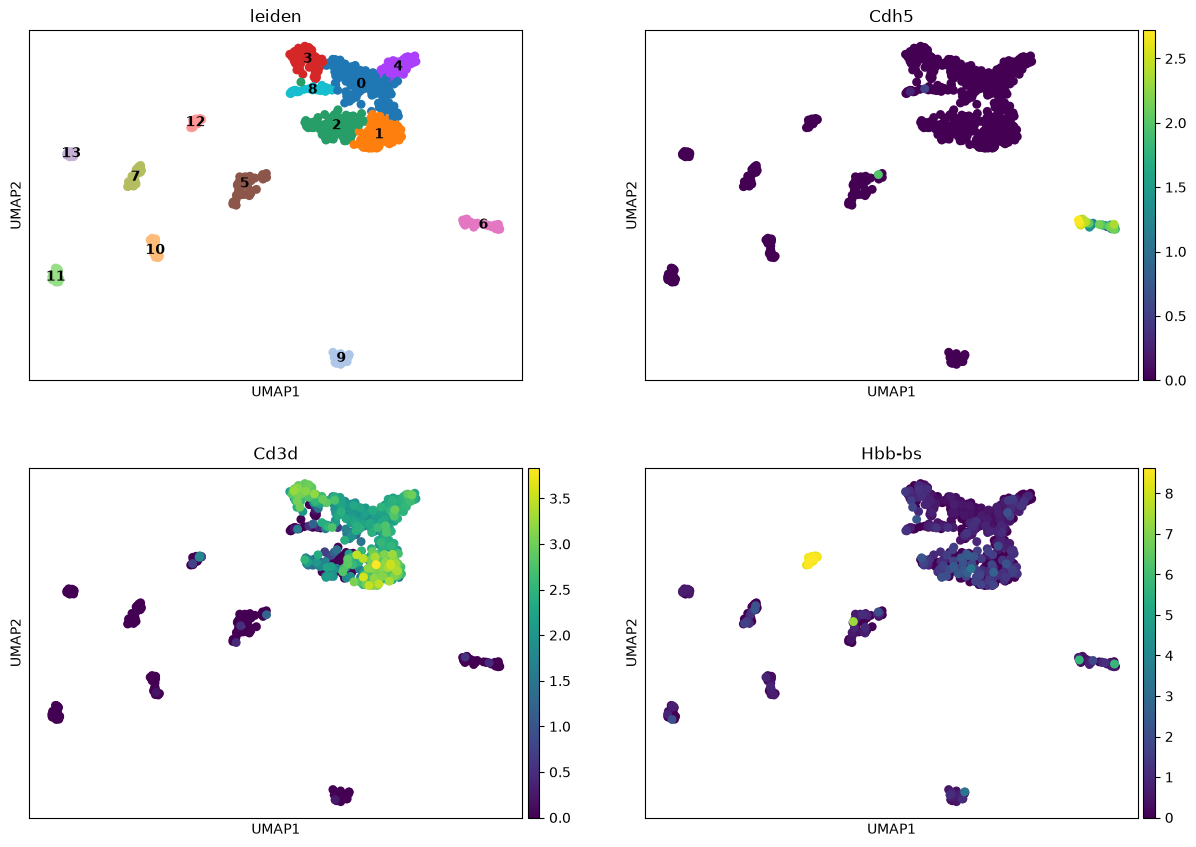

In [105]:
sc.pl.umap(adata, color=["leiden", "Cdh5", "Cd3d", "Hbb-bs"], legend_loc="on data", ncols=2)

еще можно вывести вот такую красоту :)

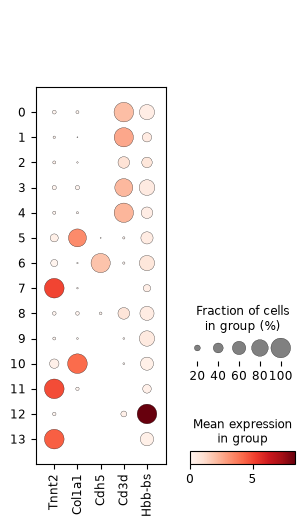

In [106]:
sc.pl.dotplot(adata, ["Tnnt2", "Col1a1", "Cdh5", "Cd3d", "Hbb-bs"], groupby="leiden")

**Итого**

- **Кардиомиоциты** - кластеры 7, 11, 13 с высоким `Tnnt2`. Их несколько, возможно это кардиомиоциты разных отделов
- **Фибробласты** - кластеры 5 и 10 с `Col1a1`
- **Эндотелиальные клетки** - кластер 6 с `Cdh5`
- **Эритроциты** - маленький кластер 12 с очень высоким `Hbb-bs`
- **T-клетки** - большое облако из кластеров 0-4 с `Cd3d`. Это немного странно, чат жпт сказал, что видимо при выделении сердца эмбриона захватили часть тимуса

Кластеры 8 и 9 выбранными генами не объясняются, для них нужно что-то еще. Но уже 12 ночи, я хочу спать :(